In [10]:
# For tips on running notebooks in Google Colab, see
# https://docs.pytorch.org/tutorials/beginner/colab
%matplotlib inline

[Learn the Basics](intro.html) \|\|
[Quickstart](quickstart_tutorial.html) \|\|
[Tensors](tensorqs_tutorial.html) \|\| **Datasets & DataLoaders** \|\|
[Transforms](transforms_tutorial.html) \|\| [Build
Model](buildmodel_tutorial.html) \|\|
[Autograd](autogradqs_tutorial.html) \|\|
[Optimization](optimization_tutorial.html) \|\| [Save & Load
Model](saveloadrun_tutorial.html)

学习基础知识 \|\| 快速入门 \|\| 张量 \|\| **数据集与数据加载器** \|\| 数据变换 \|\| 构建模型 \|\| 自动微分 \|\| 优化模型参数 \|\| 保存与加载模型

Datasets & DataLoaders 数据集与数据加载器
======================


Code for processing data samples can get messy and hard to maintain; we
ideally want our dataset code to be decoupled from our model training
code for better readability and modularity. PyTorch provides two data
primitives: `torch.utils.data.DataLoader` and `torch.utils.data.Dataset`
that allow you to use pre-loaded datasets as well as your own data.
`Dataset` stores the samples and their corresponding labels, and
`DataLoader` wraps an iterable around the `Dataset` to enable easy
access to the samples.

处理数据样本的代码可能会变得混乱且难以维护；理想情况下，我们希望数据集代码与模型训练代码解耦，以获得更好的可读性和模块化。PyTorch 提供了两个数据基本组件：`torch.utils.data.DataLoader` 和 `torch.utils.data.Dataset`，它们让你既可以使用预加载的数据集，也可以使用自己的数据。`Dataset` 存储样本及其对应的标签，`DataLoader` 则在 `Dataset` 外面包装一个可迭代对象，以便轻松访问样本。

PyTorch domain libraries provide a number of pre-loaded datasets (such
as FashionMNIST) that subclass `torch.utils.data.Dataset` and implement
functions specific to the particular data. They can be used to prototype
and benchmark your model. You can find them here: [Image
Datasets](https://pytorch.org/vision/stable/datasets.html), [Text
Datasets](https://pytorch.org/text/stable/datasets.html), and [Audio
Datasets](https://pytorch.org/audio/stable/datasets.html)

PyTorch 的领域库提供了许多预加载的数据集（例如 FashionMNIST），它们继承自 `torch.utils.data.Dataset`，并实现了针对特定数据的函数。这些数据集可用于模型的原型开发和基准测试。你可以在这里找到它们：[图像数据集](https://pytorch.org/vision/stable/datasets.html)、[文本数据集](https://pytorch.org/text/stable/datasets.html) 和 [音频数据集](https://pytorch.org/audio/stable/datasets.html)。


Loading a Dataset 加载数据集
=================

Here is an example of how to load the
[Fashion-MNIST](https://research.zalando.com/project/fashion_mnist/fashion_mnist/)
dataset from TorchVision. Fashion-MNIST is a dataset of Zalando's
article images consisting of 60,000 training examples and 10,000 test
examples. Each example comprises a 28×28 grayscale image and an
associated label from one of 10 classes.

下面是一个从 TorchVision 加载 [Fashion-MNIST](https://research.zalando.com/project/fashion_mnist/fashion_mnist/) 数据集的示例。Fashion-MNIST 是由 Zalando 商品图片组成的数据集，包含 60,000 个训练样本和 10,000 个测试样本。每个样本由一张 28×28 的灰度图像和一个标签组成，标签属于 10 个类别之一。

We load the [FashionMNIST Dataset](https://pytorch.org/vision/stable/datasets.html#fashion-mnist) with the following parameters:

我们使用以下参数加载 [FashionMNIST 数据集](https://pytorch.org/vision/stable/datasets.html#fashion-mnist)：

:   -   `root` is the path where the train/test data is stored,
    -   `train` specifies training or test dataset,
    -   `download=True` downloads the data from the internet if it\'s
        not available at `root`.
    -   `transform` and `target_transform` specify the feature and label
        transformations

*   `root` 是存储训练/测试数据的路径；
*   `train` 指定加载训练集还是测试集；
*   `download=True` 表示如果 `root` 下没有数据，就从网上下载；
*   `transform` 和 `target_transform` 分别指定对**特征**和**标签**的变换。


In [11]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

training_data = datasets.FashionMNIST(
    root='data',
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

# scale=True表示 转换数据类型的同时，按比例换算数值，让它落在新类型约定的取值范围里。
# uint8 -> 0~255
# float32 -> 0.0~1.0

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

Iterating and Visualizing the Dataset 遍历并可视化数据集
=====================================

We can index `Datasets` manually like a list: `training_data[index]`. We
use `matplotlib` to visualize some samples in our training data.

我们可以像列表一样手动索引 `Datasets`：`training_data[index]`。我们使用 `matplotlib` 来可视化训练数据中的一些样本。


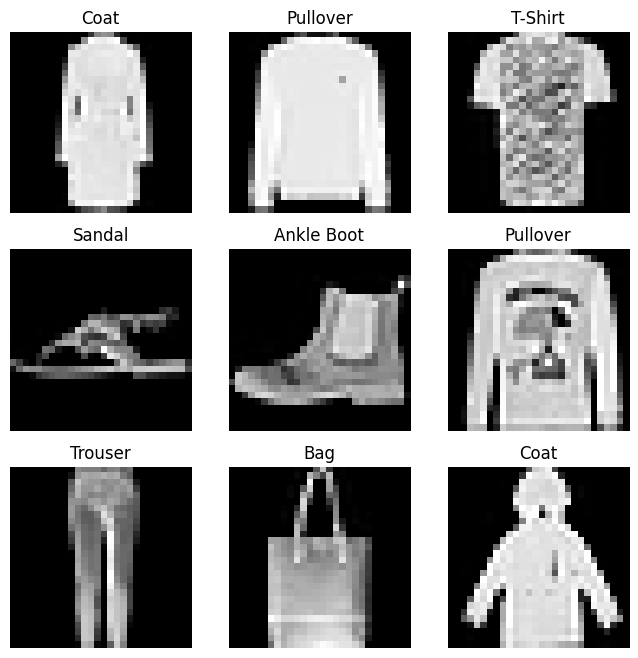

In [12]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()


------------------------------------------------------------------------


Creating a Custom Dataset for your files 为你的文件创建自定义数据集
========================================

A custom Dataset class must implement three functions:
[\_\_init\_\_]{.title-ref}, [\_\_len\_\_]{.title-ref}, and
[\_\_getitem\_\_]{.title-ref}. Take a look at this implementation; the
FashionMNIST images are stored in a directory `img_dir`, and their
labels are stored separately in a CSV file `annotations_file`.

自定义的 Dataset 类必须实现三个函数：`__init__`、`__len__` 和 `__getitem__`。来看看下面这个实现：FashionMNIST 图像存储在目录 `img_dir` 中，它们的标签则单独存储在 CSV 文件 `annotations_file` 中。

In the next sections, we\'ll break down what\'s happening in each of
these functions.

在接下来的几个小节中，我们将逐一分析这些函数里发生了什么。


In [13]:
import os
import pandas as pd
from torchvision.io import decode_image


# 自定义数据类，文件组织类似：
'''
labels.csv              img_dir/
─────────────           ├── tshirt1.jpg
tshirt1.jpg, 0          ├── tshirt2.jpg
tshirt2.jpg, 0          └── ankleboot999.jpg
ankleboot999.jpg, 9
'''
class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)    # 将csv文件读成 DataFrame
        self.img_dir = img_dir     # 记住图片所在文件夹
        self.transform = transform     # 作用在image上的变换
        self.target_transform = target_transform     # 作用在label上的变换
    
    def __len__(self):
        return len(self.img_labels)     # csv有多少行，就有多少个样本

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        # img_labels.iloc[idx, 0]是pandas按位置取值的写法，取idx行，第0列，也就是img文件名如tshirt1.jpg

        image = decode_image(img_path)  # 从磁盘读取图片文件并decode成tensor
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label


`__init__`
==========

The \_\_[init](#init__) function is run once when instantiating the
Dataset object. We initialize the directory containing the images, the
annotations file, and both transforms (covered in more detail in the
next section).

`__init__` 函数在实例化 Dataset 对象时运行一次。我们在这里初始化包含图像的目录、标注文件以及两种变换（下一节会详细介绍）。

The labels.csv file looks like: :

labels.csv 文件的内容如下：

    tshirt1.jpg, 0
    tshirt2.jpg, 0
    ......
    ankleboot999.jpg, 9


In [ ]:
def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
    self.img_labels = pd.read_csv(annotations_file)
    self.img_dir = img_dir
    self.transform = transform
    self.target_transform = target_transform



`__len__`
=========

The \_\_[len](#len__) function returns the number of samples in our
dataset.

`__len__` 函数返回数据集中的样本数量。

Example:

示例：


In [ ]:
def __len__(self):
    return len(self.img_labels)

`__getitem__`
=============

The \_\_[getitem](#getitem__) function loads and returns a sample from
the dataset at the given index `idx`. Based on the index, it identifies
the image\'s location on disk, converts that to a tensor using
`decode_image`, retrieves the corresponding label from the csv data in
`self.img_labels`, calls the transform functions on them (if
applicable), and returns the tensor image and corresponding label in a
tuple.

`__getitem__` 函数根据给定的索引 `idx` 从数据集中加载并返回一个样本。它根据索引找到图像在磁盘上的位置，用 `decode_image` 把图像转换为张量，从 `self.img_labels` 的 csv 数据中取出对应的标签，（如果有的话）对它们调用变换函数，最后以元组形式返回张量图像和对应的标签。


In [ ]:
def __getitem__(self, idx):
    img_path = os.path.join(self.img_dir, self.img_labels[idx, 0])

    image = decode_image(img_path)
    label = self.img_labels.iloc[idx, 1]

    if self.transform:
        image = self.transform(image)
    if self.target_transform:
        label = self.target_transform(label)
    return image, label

------------------------------------------------------------------------


Preparing your data for training with DataLoaders 使用 DataLoader 为训练准备数据
=================================================

The `Dataset` retrieves our dataset\'s features and labels one sample at
a time. While training a model, we typically want to pass samples in
\"minibatches\", reshuffle the data at every epoch to reduce model
overfitting, and use Python\'s `multiprocessing` to speed up data
retrieval.

`Dataset` 每次检索数据集中一个样本的特征和标签。训练模型时，我们通常希望以“小批量”（minibatch）的形式传入样本，在每个 epoch 重新打乱数据以减少模型过拟合，并使用 Python 的 `multiprocessing` 加速数据读取。

`DataLoader` is an iterable that abstracts this complexity for us in an
easy API.

`DataLoader` 是一个可迭代对象，它用简单的 API 为我们屏蔽了这些复杂性。


In [20]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)



Iterate through the DataLoader 遍历 DataLoader
==============================

We have loaded that dataset into the `DataLoader` and can iterate
through the dataset as needed. Each iteration below returns a batch of
`train_features` and `train_labels` (containing `batch_size=64` features
and labels respectively). Because we specified `shuffle=True`, after we
iterate over all batches the data is shuffled (for finer-grained control
over the data loading order, take a look at
[Samplers](https://pytorch.org/docs/stable/data.html#data-loading-order-and-sampler)).

我们已经把数据集加载到 `DataLoader` 中，可以按需遍历数据集。下面的每次迭代都会返回一批 `train_features` 和 `train_labels`（分别包含 `batch_size=64` 个特征和标签）。由于我们指定了 `shuffle=True`，遍历完所有批次后数据会被打乱（如需更细粒度地控制数据加载顺序，请参阅 [Samplers](https://pytorch.org/docs/stable/data.html#data-loading-order-and-sampler)）。


Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


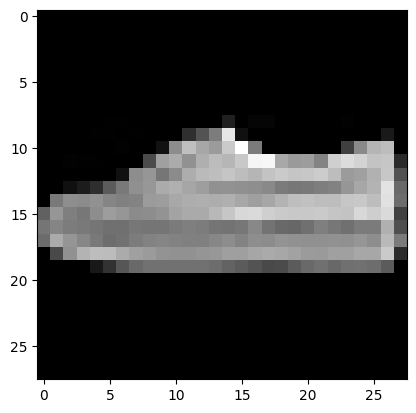

Label: 7


In [21]:
# Display image and label
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

------------------------------------------------------------------------


Further Reading 延伸阅读
===============

-   [torch.utils.data API](https://pytorch.org/docs/stable/data.html)

*   [torch.utils.data API 文档](https://pytorch.org/docs/stable/data.html)
